<center><strong>Pemrosesan Bahasa Natural</strong><br />
<strong><font color="blue">Rekayasa Kecerdasan Artifisial</font></strong><br />
</center>

<strong>Outline pertemuan minggu ke-5</strong><br />
<li> Pendahuluan Klasifikasi </li>
<li> K-NN, Naive Byaes, Decision Tree, SVM </li>
<li> Visualisasi dengan boxplot </li>


<p><img alt="" src="figures/56_Supervised VS unsupervised.png" style="height:500px; width:1153px" /></p>

### K-Nearest Neighbour (K-NN)
- Classifier yang paling sederhana
- Dapat digunakan untuk permaslaahn klasifikasi dan regresi

<strong> Kelebihan: </strong>
- Efisien untuk data berukuran besar
- Sederhana, mudah diimplementasikan
- Mudah dimodikasi (perhitungan jarak)
- Menangani data multiclass dengan mudah

<strong> Kekurangan: </strong>
- Semakin besar data semakin lambat performanya (menghitung NN)
- Memerlukan jumlah K optimal
- Tidak cocok untuk imbalance data

<p><img alt="" src="figures/6_kNN.JPG" style="height:300px; width:711px" /></p>

In [5]:
# load data pickle dari 20newsgroups yang didapat dari pertemuan 4
import pickle
import os

src_name = "20newsgroup.pckl"
src_path = os.path.join("/Users/sittiaminah/Documents/SEMESTER 4/NLP/20newsgroup.pckl")
with open(src_path, 'rb') as fin:
    data = pickle.load(fin)

docs = [doc for doc in data.data]
label = data.target

print('DONE!')

DONE!


In [6]:
# preprocessing
import re
from nltk import sent_tokenize
from nltk import word_tokenize

def preprocess(doc):
    sents = sent_tokenize(doc)
    sents_tok = list() # tokenisasi kalimat
    for s in sents:
        s = s.strip().lower() # case folding dan menghilangkan new line
        s = s.replace("\n", " ") # menggantikan \n dengan spasi
        s = re.sub(r'[^a-zA-Z0-9 ]', ' ', s) # menghapus simbol
        s = re.sub(' +', ' ', s) # menghapus repetitive space

        sents_tok.append(s)

    return " ".join(sents_tok)

docs_clear = list()
for d in docs:
    docs_clear.append(preprocess(d))

In [7]:
# representasi vektor dengan VSM-TFIDF
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(max_df=0.95, min_df=2)
X = tfidf_vectorizer.fit_transform(docs_clear)
print(X.shape)

(1653, 10721)


In [8]:
print(len(label))
print(len(docs_clear))
print(len(X.getnnz(1)))
print(X.shape)

1653
1653
1653
(1653, 10721)


In [9]:
# Cleaning noise
# Hapus label yang memiliki row = 0 pada tfidf-nya
# Hapus row yang memiliki nilai 0
Y = label[X.getnnz(1)>0]
X_clear = X[X.getnnz(1)>0]

# Hapus dokumen yang memiliki nilai row 0
docs_nonzero = list()
for i, d in enumerate(X.getnnz(1)>0):
    if d:
        docs_nonzero.append(docs_clear[i])

print(X_clear.shape, len(Y), len(docs_nonzero))

(1590, 10721) 1590 1590


In [10]:
# Membagi data menjadi dua yaitu data training dan data testing
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X_clear, Y, test_size=.3, random_state=8989)
print(X_train.shape, X_test.shape)

(1113, 10721) (477, 10721)


In [14]:
# KNN menggunakan scikit-learn library
# http://scikit-learn.org/stable/modules/neighbors.html
from sklearn import neighbors

K = 10
weights = 'distance'
kNN = neighbors.KNeighborsClassifier(n_neighbors=K, weights=weights)
kNN.fit(X_train, Y_train)
print('Done!')

Done!


In [15]:
# Prediksi dengan KNN
Y_knn = kNN.predict(X_test)

In [16]:
# Evaluasi dengan akurasi
from sklearn.metrics import accuracy_score

accuracy_score(Y_test, Y_knn)

0.7274633123689728

<h3 id="Latihan:"><font color="blue">Latihan 1:</font></h3>

<ul>
    <li> Mengapa perlu dilakukan data splitting (training dan testing)?</li>
    <li> Apakah rasio splitting berpengaruh pada performa dari model? </li>
    <li> Cobalah beberapa model dengan merubah nilai dari parameter K, berapakah nilai K yang paling optimal? </li>

In [21]:
# Kerjakan latihan 1 pada cell berikut ini

"""1. Supaya kita tau performa asli model kita. Kita akan splitting jadi training data (untuk melatih data) 
dan testing data (untuk menguji model seolah-olah data baru)"""

""" 2. Berpengaruh. Klo training terlalu sedikit, model kurang belajar, dan performa jadi jelek.
Klo training terlalu banyak, model jadi overfit, jadi jelek juga klo diuji."""

K = 10
weights = 'distance'
kNN = neighbors.KNeighborsClassifier(n_neighbors=K, weights=weights)
kNN.fit(X_train, Y_train)
Y_knn = kNN.predict(X_test)
print("K=10 : ",accuracy_score(Y_test, Y_knn))

K = 5
weights = 'distance'
kNN = neighbors.KNeighborsClassifier(n_neighbors=K, weights=weights)
kNN.fit(X_train, Y_train)
Y_knn = kNN.predict(X_test)
print("K=5 : ",accuracy_score(Y_test, Y_knn))

K = 3
weights = 'distance'
kNN = neighbors.KNeighborsClassifier(n_neighbors=K, weights=weights)
kNN.fit(X_train, Y_train)
Y_knn = kNN.predict(X_test)
print("K=3 : ",accuracy_score(Y_test, Y_knn))

K=10 :  0.7274633123689728
K=5 :  0.80083857442348
K=3 :  0.8218029350104822


### Naive Bayes Classifier

Metode klasifikasi dengan pendekatan probabilitas yang didasarkan pada teorema <strong>Bayes</strong>. Berasumsi bahwa semua fitur adalah independen dan memiliki kontribusi yang sama.

<p><img alt="" src="figures/naive_bayes.png" style="width: 400px ; height: 220px" /></p>

<strong>Dimana:</strong>
- x : fitur
- c : kelas
- P(c|x) : Probabilitas kelas c diberikan x sebagai fitur

<strong> Kelebihan:</strong>
- Cepat dan mudah diimplementasikan
- Cocok untuk multiclass
- Dapat bekerja dengan baik untuk data berdimensi tinggi (high-dimensional data)

<strong> Kekurangan:</strong>
- Asumsi bahwa semua fitur independen terkadang tidak sesuai dengan real-life data

In [22]:
# Menggunakan data sebelumnya
# Naive bayes menggunakan library scikit-learn
# http://scikit-learn.org/stable/modules/naive_bayes.html
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()
nbc = gnb.fit(X_train.toarray(), Y_train)
Y_nbc = nbc.predict(X_test.toarray())

accuracy_score(Y_test, Y_nbc)

0.870020964360587

### Decision Tree

Decision tree menggunakan rule-based (if else condition) pada sebuah tree untuk membangan sebuah model. Decision tree dapat dipergunakan untuk categorical ataupun numerical data.

<p><img alt="" src="figures/6_DT.png" style="height:336px; width:904px" /></p>

<p> Contoh: </p>
<p><img alt="" src="figures/6_DT_meme.png" style="height:342px; width:460px" /></p>

<strong>Kelebihan:</strong>
- Mudah untuk dipahami, cocok untuk visualisasi
- Dapat digunakan untuk categorical maupun numerical data
- non-parametric model
- Robust terhadap outliers dan missing values

<strong>Kekurangan:</strong>
- Sering overfit





In [23]:
# Decision Tree dengan library scikit-learn
#http://scikit-learn.org/stable/modules/tree.html
from sklearn import tree

DT = tree.DecisionTreeClassifier()
DT = DT.fit(X_train, Y_train)
Y_DT = DT.predict(X_test)

accuracy_score(Y_test, Y_DT)

0.6519916142557652

In [24]:
!pip install pydotplus

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for pydotplus: filename=pydotplus-2.0.2-py3-none-any.whl size=24633 sha256=e6bc6d760af27450224e4a700b90b5ac7dfca088128313c9b7839893bc5350f6
  Stored in directory: /Users/sittiaminah/Library/Caches/pip/wheels/77/54/7c/c8077b6151c819495492300386cf9b151a954259d1a658c63b
Successfully built pydotplus


In [25]:
# Visualisasi tree
import pydotplus
from sklearn.externals.six import StringIO
from IPython.display import Image
from sklearn.tree import export_graphviz

dot_data = StringIO()
export_graphviz(DT, out_file=dot_data, filled=True, rounded=True)
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())
Image(graph.create_png())

ModuleNotFoundError: No module named 'sklearn.externals.six'

### Random Forest

<p><img alt="" src="figures/5_RandomForest.png" style="width: 592px; height: 444px;" /></p>

<p>Terdiri dari beberapa decision tree. Merupakan ensamble algorithm yang mengambil hasil dari beberapa decision tree. </p>

<strong>Kelenihan:</strong>
- Robust terhadap outlier
- Dapat bekerja dengan baik pada non-linear data
- Dapat menurunkan risiko overfitting
- Dapat bekerja dengan efisien pada data set yang besar

<strong>Kekurangan:</strong>
- Bias ketika dipergunakan untuk categorical variabel
- lambat

In [26]:
# Random Forest
# http://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
from sklearn.ensemble import RandomForestClassifier

RandomForest = RandomForestClassifier()
RandomForest.fit(X_train, Y_train)
Y_RF = RandomForest.predict(X_test)
accuracy_score(Y_test, Y_RF)

0.7924528301886793

### Support Vector Machine (SVM)

<p><img alt="" src="figures/6_SVM.jpg" style="height: 262px ; width: 232px" /><img alt="" src="figures/svm_opt.png" style="width: 300px; height: 106px;" /></p>
<p>SVM melakukan plotting data ke dalam n-dimensi. Klasifikasi dilakukan dengan mencari hyper-plane yg memisahkan dua kelas.</p>

<h4> SVM kernel </h4>
<p> SVM kernel digunakan untuk data yang bersifat non-linear. Data yang bersifat non-linear tidak dapat dipisahkan dengan menggunakan garis lurus seperti pada data linear. Untuk mengatasi permasalahan tersebut digunakan <strong>kernel trick</strong>. Kernel trick mentransformasikan data ke dalam dimensi yg lebih tinggi agar lebih mudah dipisahkan.</p>

<strong> Beberapa kernel SVM:</strong>
- Linear
- Polynomial
- RBF
- Sigmoid


<h4>SVM multiclass</h4>

<p><img alt="" src="figures/6_SVM_Ova.jpg" style="height:314px; width:432px" /></p>

<strong>Kelebihan:</strong>
- Dapat bekerja dengan efektif pada dataset berukuran kecil
- Memiliki performa yang baik untuk data berdimensi tinggi
- Relatif efisien dalam penggunaan memori

<strong>Kekurangan:</strong>
- Kurang cocok untuk dataset berukuran besar
- Kurang efektif untuk data yang memiliki banyak noise

In [27]:
# SVM
# http://scikit-learn.org/stable/modules/svm.html
from sklearn import svm

dSVM = svm.SVC(decision_function_shape='ovo') # one versus one SVM
dSVM.fit(X_train, Y_train)
Y_SVM = dSVM.predict(X_test)
accuracy_score(Y_test, Y_SVM)

0.8721174004192872

In [28]:
# Menggunakan kernel trick
# Default kernel dari fungsi SVM pada scikit learn adalah 'RBF'
list_kernel = ['linear', 'poly', 'rbf', 'sigmoid']
for kernel in list_kernel:
    dSVM = svm.SVC(kernel=kernel, gamma='auto')
    dSVM.fit(X_train, Y_train)
    y_SVM = dSVM.predict(X_test)
    print(kernel, ':', accuracy_score(Y_test, y_SVM))

linear : 0.8805031446540881
poly : 0.36268343815513626
rbf : 0.36268343815513626
sigmoid : 0.36268343815513626


### Cross Validation

<p>Cross validation dipergunakan untuk memvalidasi hasil dari suatu model, memastikan objektifitas dari hasil. </p>

<p><img alt="" src="figures/6_Cross_validation.png" style="height:274px; width:485px" /></p>

In [29]:
# Cross validation
# http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html
from sklearn.model_selection import cross_val_score
import time

svm_ = svm.SVC(kernel='linear')
start = time.time()
scores_svm = cross_val_score(svm_, X_clear, Y, cv=10) # perhatikan sekarang kita menggunakan seluruh data
timepros = time.time() - start

print("Accuracy SVM: %0.2f (+/- %0.2f), Waktu = %0.3f detik" % (scores_svm.mean(), scores_svm.std() * 2, timepros))

Accuracy SVM: 0.91 (+/- 0.04), Waktu = 10.728 detik


In [30]:
# Bagaimana dengan k-NN ?
mulai = time.time()
scores_kNN = cross_val_score(kNN, X_clear, Y, cv=10) # perhatikan sekarang kita menggunakan seluruh data
waktu = time.time() - mulai
# Interval Akurasi 95 CI
print("Accuracy k-NN: %0.2f (+/- %0.2f), Waktu = %0.3f detik" % (scores_kNN.mean(), scores_kNN.std() * 2, waktu))

Accuracy k-NN: 0.83 (+/- 0.05), Waktu = 0.150 detik


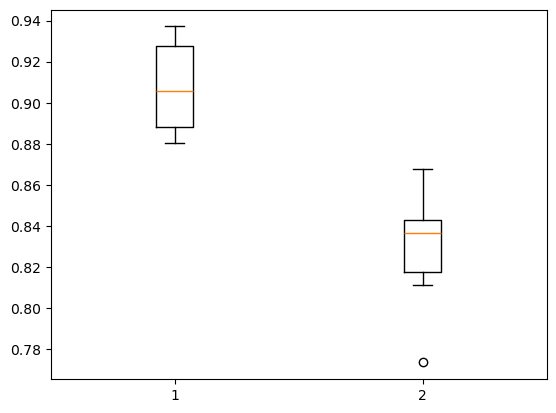

In [31]:
# Visualisasi hasil dengan boxplot
# Buat BoxPlotnya
import matplotlib.pyplot as plt
import numpy as np

Data = [scores_svm, scores_kNN]
L = ['SVM', 'kNN']

fig, ax = plt.subplots()

# Creating plot
plt.boxplot(Data)

# show plot
plt.show()

### Bagaimana jika ingin menggunakan word embedding sebagai representasi vektornya?

In [32]:
# Melakukan persiapan dokumen
# yang digunakan sebagai data adalah docs_nonzero
doc_gensim = [word_tokenize(d) for d in docs_nonzero]

In [34]:
# membuat Word Embeddingnya
from gensim.models import FastText

N = len(doc_gensim)
dim = 300 # Jumlah neurons = ukuran vektor = jumlah kolom
model_FT = FastText(doc_gensim, vector_size=dim, window=5, min_count=1, workers=-1)

In [35]:
# NOTE:
# tidak dapat langsung menggunakan hasil dari word embedding
# representasi vektor embedding adalah representasi per kata
# harus mengkonversikan dari word embedding ke dalam vektor space
# dokumen x words
def we2vsm(model_we, data_we):
    N = len(data_we)
    L = model_we.vector_size
    vsm_we = np.empty([N, L], dtype=np.float64) # inisialisasi matriks
    for i,d in enumerate(data_we):
        tmp = np.zeros([1, L], dtype=np.float64)
        count = 0
        for t in d:
            try:
                tmp += model_we.wv.__getitem__([t])
                count += 1
            except:
                pass
        if count>0:
            vsm_we[i] = tmp/count
    return vsm_we

In [36]:
vsm_we = we2vsm(model_FT, doc_gensim)
vsm_we.shape

(1590, 300)

#### Setelah memiliki bentuk representasi dokumen, langkah selanjutnya adalah melakukan proses klasifikasi seperti yang telah dicontohkan sebelumnya

<h3 id="Latihan:"><font color="blue">Latihan 2:</font></h3>

- Lakukan klasifikasi dengan representasi yang telah diperoleh dari proses word embedding (vsm_we) dengan berbagai metode (knn, desicion tree, random forest, naive bayes, dan VSM)
- Visualisasikan hasilnya
- Bandingkan hasilnya dengan representasi dari VSM-TFIDF

In [43]:
# Kerjakan latihan 2 pada cell berikut ini

doc_gensim = [word_tokenize(d) for d in docs_nonzero]
model_FT = FastText(doc_gensim, vector_size=300, window=5, min_count=1, workers=-1)

vsm_we = we2vsm(model_FT, doc_gensim)

X_train, X_test, y_train, y_test = train_test_split(
    vsm_we, Y, test_size=0.2, random_state=42
)

In [47]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)

acc_knn = accuracy_score(y_test, y_pred_knn)
print("Accuracy KNN :", acc_knn)

Accuracy KNN : 0.5031446540880503


In [48]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier()
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

acc_dt = accuracy_score(y_test, y_pred_dt)
print("Accuracy Decision Tree :", acc_dt)

Accuracy Decision Tree : 0.46226415094339623


In [49]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier()
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

acc_rf = accuracy_score(y_test, y_pred_rf)
print("Accuracy Random Forest :", acc_rf)

Accuracy Random Forest : 0.5660377358490566


In [50]:
from sklearn.naive_bayes import GaussianNB
nb = GaussianNB()
nb.fit(X_train, y_train)
y_pred_nb = nb.predict(X_test)

acc_nb = accuracy_score(y_test, y_pred_nb)
print("Accuracy Naive Bayes :", acc_nb)

Accuracy Naive Bayes : 0.4371069182389937


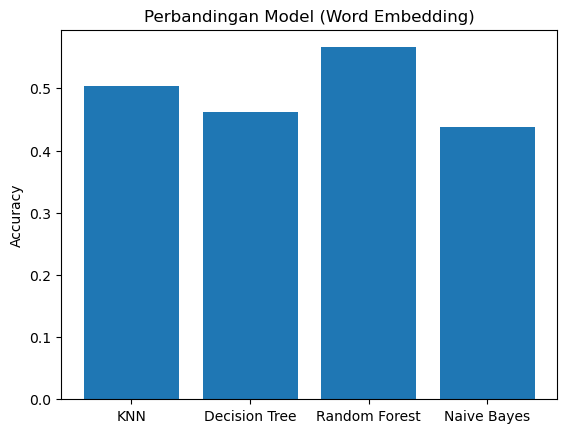

In [51]:
import matplotlib.pyplot as plt

results_we = {
    "KNN": acc_knn,
    "Decision Tree": acc_dt,
    "Random Forest": acc_rf,
    "Naive Bayes": acc_nb
}

names = list(results_we.keys())
values = list(results_we.values())

plt.bar(names, values)
plt.title("Perbandingan Model (Word Embedding)")
plt.ylabel("Accuracy")
plt.show()

In [53]:
# tf idf
X_train_tfidf, X_test_tfidf, y_train, y_test = train_test_split(
    X_clear.toarray(), Y, test_size=0.2, random_state=42
)

In [56]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_tfidf, y_train)
y_pred = knn.predict(X_test_tfidf)
acc_knn_tfidf = accuracy_score(y_test, y_pred)

dt = DecisionTreeClassifier()
dt.fit(X_train_tfidf, y_train)
acc_dt_tfidf = accuracy_score(y_test, dt.predict(X_test_tfidf))

rf = RandomForestClassifier()
rf.fit(X_train_tfidf, y_train)
acc_rf_tfidf = accuracy_score(y_test, rf.predict(X_test_tfidf))

nb = GaussianNB()
nb.fit(X_train_tfidf, y_train)
acc_nb_tfidf = accuracy_score(y_test, nb.predict(X_test_tfidf))

In [58]:
results_compare = {
    "KNN_WE": acc_knn,
    "KNN_TFIDF": acc_knn_tfidf,
    "DT_WE": acc_dt,
    "DT_TFIDF": acc_dt_tfidf,
    "RF_WE": acc_rf,
    "RF_TFIDF": acc_rf_tfidf,
    "NB_WE": acc_nb,
    "NB_TFIDF": acc_nb_tfidf
}

results_compare

{'KNN_WE': 0.5031446540880503,
 'KNN_TFIDF': 0.7830188679245284,
 'DT_WE': 0.46226415094339623,
 'DT_TFIDF': 0.6320754716981132,
 'RF_WE': 0.5660377358490566,
 'RF_TFIDF': 0.8144654088050315,
 'NB_WE': 0.4371069182389937,
 'NB_TFIDF': 0.8364779874213837}

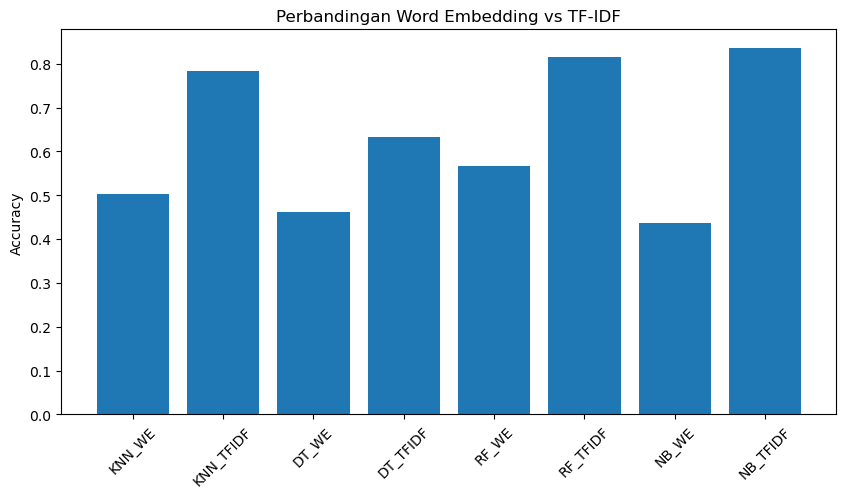

In [59]:
names = list(results_compare.keys())
values = list(results_compare.values())

plt.figure(figsize=(10,5))
plt.bar(names, values)
plt.xticks(rotation=45)
plt.title("Perbandingan Word Embedding vs TF-IDF")
plt.ylabel("Accuracy")
plt.show()